In [1139]:
import cv2
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path


In [1140]:
class BrailleGenerator:
    def __init__(
        self,
        img_size: tuple[int, int] = (1448, 1024),
        scale: float | None = None,
        small_scale_ratio: float = 0.35,
        bbox_pad_mm: float = 0.25,
    ) -> None:
        self.img_size = img_size
        self.scale = scale
        if scale is None:
            if random.random() < small_scale_ratio:
                self.scale = random.uniform(3.2, 4.0)   # ~15 px cell width
            else:
                self.scale = random.uniform(4.5, 5.5)   # ~22–30 px cell width
        else:
            self.scale = scale
        self.bbox_pad = bbox_pad_mm * self.scale

        # Standard Marburg Medium dimensions (mm to pixels)
        self.dot_rad   = (1.5 / 2) * self.scale
        self.px_h_dot  = 2.5 * self.scale   
        self.px_v_dot  = 2.5 * self.scale   
        self.px_cell_w = 6.0 * self.scale   
        self.px_line_h = 10.0 * self.scale  

    def id_to_bits(self, char_id: int) -> str:
        """Convert a 0-based character index to a 6-bit Braille dot string."""
        char_id = max(0, min(62, char_id))
        binary = format(char_id + 1, "06b")
        return binary[::-1]  # LSB first: dot 1 at index 0

    def generate_wear_map(self) -> np.ndarray:
        """Smooth 0..1 field: 1 = heavily worn/rubbed area, 0 = pristine."""
        small = np.random.uniform(0, 1, (self.img_size[0] // 40, self.img_size[1] // 40))
        wear = cv2.resize(small.astype(np.float32), (self.img_size[1], self.img_size[0]),
                        interpolation=cv2.INTER_CUBIC)
        wear = cv2.GaussianBlur(wear, (0, 0), sigmaX=self.scale * 8)
        wear = (wear - wear.min()) / (wear.max() - wear.min() + 1e-6)
        return wear ** 3   # bias toward mostly-pristine with a few worn patches

    def degrade_bump(self, bump: np.ndarray, mode: str) -> np.ndarray:
        """Randomly wear, smear, or tear a single dot's kernel."""
        h, w = bump.shape
        if mode == "worn":
            # uniform height loss — dot pressed flatter over time
            return bump * random.uniform(0.5, 0.8)

        if mode == "smear":
            # directional motion blur simulating rubbed/dragged ink
            length = random.randint(2, max(2, int(w * 0.3)))
            # length = 2
            angle = random.uniform(0, 360)
            kernel = np.zeros((length, length), dtype=np.float32)
            kernel[length // 2, :] = 1.0
            M = cv2.getRotationMatrix2D((length / 2, length / 2), angle, 1)
            kernel = cv2.warpAffine(kernel, M, (length, length))
            kernel /= kernel.sum() + 1e-6
            return cv2.filter2D(bump, -1, kernel)

        if mode == "torn":
            # smooth random blob mask carves away part of the dot
            low = np.random.normal(0, 1, (10, 10)).astype(np.float32)
            blob = cv2.resize(low, (w, h), interpolation=cv2.INTER_CUBIC)
            blob = cv2.GaussianBlur(blob, (0, 0), sigmaX=w * 0.15)
            blob = (blob - blob.min()) / (blob.max() - blob.min() + 1e-6)
            thresh = 0.9
            mask = np.clip((blob - thresh) / (1 - thresh), 0, 1)
            return bump * mask

        return bump

    def create_soft_bump(self, radius: float) -> np.ndarray:
        """Return a cosine-shaped height kernel for a single Braille dot."""
        size = int(radius * 4)
        if size % 2 == 0:
            size += 1
        kernel = np.zeros((size, size), dtype=np.float32)
        center = size // 2
        for i in range(size):
            for j in range(size):
                d = np.sqrt((i - center) ** 2 + (j - center) ** 2)
                if d < radius:
                    kernel[i, j] = np.cos(min(1.0, d / radius) * (np.pi / 2)) ** 1.4
        return kernel
    
    def create_embossed_bump(
        self,
        radius: float,
        top_ratio: float = 0.4,      #smaller flat area, more shoulder
        falloff_power: float = 0.6,   #lower = gentler, more rounded falloff
        height_scale: float = 0.35,    # NEW — see below
        upsample: int = 100,
    ) -> np.ndarray:
        radius = radius - 0.4
        falloff_power = falloff_power + random.uniform(-0.1, 0.1)
        size = int(radius * 4)
        if size % 2 == 0:
            size += 1

        hi = size * upsample
        center = hi / 2.0 - 0.5

        radius_hi = radius * upsample
        top_radius_hi = radius_hi * top_ratio

        yy, xx = np.mgrid[0:hi, 0:hi].astype(np.float32)
        d = np.sqrt((yy - center) ** 2 + (xx - center) ** 2)

        kernel_hi = np.zeros((hi, hi), dtype=np.float32)
        kernel_hi[d <= top_radius_hi] = 1.0

        edge_mask = (d > top_radius_hi) & (d < radius_hi)
        span = max(radius_hi - top_radius_hi, 1e-6)
        t = np.clip((d - top_radius_hi) / span, 0.0, 1.0)
        kernel_hi[edge_mask] = np.cos(t[edge_mask] * (np.pi / 2)) ** falloff_power

        kernel = cv2.resize(kernel_hi, (size, size), interpolation=cv2.INTER_AREA)
        return kernel * height_scale

    def apply_vignette(self, img: np.ndarray, strength: float = 0.2) -> np.ndarray:
        """Darken the edges of a 2-D float32 height map."""
        rows, cols = img.shape[:2]
        kx = cv2.getGaussianKernel(cols, cols / 2)
        ky = cv2.getGaussianKernel(rows, rows / 2)
        vignette = ky * kx.T
        vignette = vignette / vignette.max()
        return img * ((1 - strength) + strength * vignette)

    def generate_paper_texture(self) -> np.ndarray:
        """Return a float32 2-D array simulating paper grain and cloud noise."""
        texture = np.full(self.img_size, 1.01, dtype=np.float32)
        grain = np.random.normal(0, 0.0275, self.img_size)
        small_noise = np.random.normal(
            0, 0.08, (self.img_size[0] // 20, self.img_size[1] // 20)
        )
        clouds = cv2.resize(
            small_noise, (self.img_size[1], self.img_size[0]),
            interpolation=cv2.INTER_CUBIC,
        )
        clouds = cv2.GaussianBlur(clouds, (15, 15), 0)
        return texture + grain + (clouds * 0.005)

    def apply_color_tint(self, img: np.ndarray) -> np.ndarray:
        """
        Apply a random warm/cool colour tint to a 3-channel float32 BGR image.

        Temperature ranges from -1.0 (cool) to +1.0 (warm).
        """
        temp = random.uniform(-1.1, 1.0)
        brightness = random.uniform(0.85, 1.0)

        if temp > 0:  # warm: attenuate blue and green slightly
            b_mult = 1.0 - (temp * 0.45)
            g_mult = 1.0 - (temp * 0.20)
            r_mult = 1.0
        else:          # cool: attenuate red and green slightly
            b_mult = 1.0
            g_mult = 1.0 - (abs(temp) * 0.05)
            r_mult = 1.0 - (abs(temp) * 0.20)

        img[:, :, 0] *= r_mult * brightness
        img[:, :, 1] *= g_mult * brightness
        img[:, :, 2] *= b_mult * brightness
        return img

    def apply_perspective_skew(
        self,
        img: np.ndarray,
        max_skew_px: int = 180,
        max_rot_deg: float = 2.5,
    ) -> tuple[np.ndarray, np.ndarray]:
        """
        Apply a random 3-D perspective distortion or 2-D rotation.

        Returns
        (warped_image, perspective_matrix)
            The 3x3 homography is used downstream to warp annotation corners.
        """
        h, w = img.shape[:2]
        skew_factor = max_skew_px * (self.scale / 10)

        src_pts = np.float32([[0, 0], [w - 1, 0], [0, h - 1], [w - 1, h - 1]])
        dst_pts = src_pts.copy()

        style = random.choice(["3d_pitch", "3d_yaw", "3d_combined", "2d_rotate"])

        if style == "3d_pitch":
            tilt = random.uniform(skew_factor * 0.2, skew_factor * 2.5)
            if random.choice([True, False]):
                dst_pts[0][0] += tilt; dst_pts[1][0] -= tilt
                dst_pts[0][1] += tilt; dst_pts[1][1] += tilt
            else:
                dst_pts[2][0] += tilt; dst_pts[3][0] -= tilt
                dst_pts[2][1] -= tilt; dst_pts[3][1] -= tilt

        elif style == "3d_yaw":
            tilt = random.uniform(skew_factor * 0.2, skew_factor * 2.5)
            if random.choice([True, False]):
                dst_pts[0][1] += tilt; dst_pts[2][1] -= tilt
                dst_pts[0][0] += tilt; dst_pts[2][0] += tilt
            else:
                dst_pts[1][1] += tilt; dst_pts[3][1] -= tilt
                dst_pts[1][0] -= tilt; dst_pts[3][0] -= tilt

        elif style == "3d_combined":
            px = random.uniform(skew_factor * 0.5, skew_factor * 2.0)
            py = random.uniform(skew_factor * 0.5, skew_factor * 2.0)
            corner = random.choice([0, 1, 2, 3])
            if corner == 0:
                dst_pts[0][0] += px; dst_pts[0][1] += py
                dst_pts[1][1] += py * 0.6; dst_pts[2][0] += px * 0.6
            elif corner == 1:
                dst_pts[1][0] -= px; dst_pts[1][1] += py
                dst_pts[0][1] += py * 0.6; dst_pts[3][0] -= px * 0.6
            elif corner == 2:
                dst_pts[2][0] += px; dst_pts[2][1] -= py
                dst_pts[0][0] += px * 0.6; dst_pts[3][1] -= py * 0.6
            else:
                dst_pts[3][0] -= px; dst_pts[3][1] -= py
                dst_pts[1][0] -= px * 0.6; dst_pts[2][1] -= py * 0.6

        elif style == "2d_rotate":
            angle_rad = np.radians(random.uniform(-max_rot_deg, max_rot_deg))
            cx, cy = w / 2, h / 2
            for i in range(4):
                x, y = src_pts[i]
                rx = cx + (x - cx) * np.cos(angle_rad) - (y - cy) * np.sin(angle_rad)
                ry = cy + (x - cx) * np.sin(angle_rad) + (y - cy) * np.cos(angle_rad)
                dst_pts[i] = [rx, ry]

        M = cv2.getPerspectiveTransform(src_pts, dst_pts)
        warped = cv2.warpPerspective(
            img, M, (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_REPLICATE,
        )
        return warped, M

    def calculate_lighting(
        self,
        total_h: np.ndarray,
        azimuth_deg: float = 225.0,
        elevation_deg: float = 45.0,
        intensity: float = 0.3,
    ) -> np.ndarray:
        """Compute a diffuse-lighting shading layer from a height map."""
        dzdx = cv2.Sobel(total_h, cv2.CV_32F, 1, 0, ksize=3)
        dzdy = cv2.Sobel(total_h, cv2.CV_32F, 0, 1, ksize=3)

        az = np.radians(azimuth_deg)
        el = np.radians(elevation_deg)
        L = np.array(
            [np.cos(el) * np.cos(az), np.cos(el) * np.sin(az), np.sin(el)],
            dtype=np.float32,
        )

        mag = np.sqrt(dzdx ** 2 + dzdy ** 2 + 1)
        nx, ny, nz = -dzdx / mag, -dzdy / mag, 1.0 / mag

        diffuse = nx * L[0] + ny * L[1] + nz * L[2]
        return (diffuse - 1.0) * intensity

    def generate_light_gradient(self, azimuth_deg: float, strength: float = 0.12) -> np.ndarray:
        """
        Creates a linear gradient across the image aligned with the light's azimuth.
        The side facing the light source will be brighter, falling off to the opposite side.
        """
        h, w = self.img_size
        # Create normalized coordinate grids centered at 0.0 ranging from -1.0 to 1.0
        y = np.linspace(-1.0, 1.0, h, dtype=np.float32)
        x = np.linspace(-1.0, 1.0, w, dtype=np.float32)
        xv, yv = np.meshgrid(x, y)

        # Convert azimuth to radians to find the light direction vector
        az_rad = np.radians(azimuth_deg)
        ux = np.cos(az_rad)
        uy = np.sin(az_rad)

        # Project the coordinates onto the light direction vector
        # This yields positive values in the direction of the light, negative away from it
        gradient = (xv * ux + yv * uy) / np.sqrt(2.0)  # Normalize division to keep range close to [-1, 1]

        # Scale by strength parameter
        return gradient * strength

    def generate_wear_map(self) -> np.ndarray:
        """Smooth 0..1 field: 1 = heavily worn/rubbed area, 0 = pristine."""
        small = np.random.uniform(0, 1, (self.img_size[0] // 40, self.img_size[1] // 40))
        wear = cv2.resize(small.astype(np.float32), (self.img_size[1], self.img_size[0]),
                        interpolation=cv2.INTER_CUBIC)
        wear = cv2.GaussianBlur(wear, (0, 0), sigmaX=self.scale * 8)
        wear = (wear - wear.min()) / (wear.max() - wear.min() + 1e-6)
        return wear ** 3   # bias toward mostly-pristine with a few worn patches

    def generate_page(
        self,
        allowed_chars: list[int] | None = None,
        margin_mm: float = 20.0,
        space_prob: float = 0.35,
        apply_skew: bool = True,
    ) -> tuple[np.ndarray, list[str]]:
        if allowed_chars is None:
            allowed_chars = list(range(63))

        recto_h = np.zeros(self.img_size, dtype=np.float32)
        verso_h = np.zeros(self.img_size, dtype=np.float32)

        bump = self.create_embossed_bump(self.dot_rad)
        bh, bw = bump.shape
        offset = bh // 2

        margin = int(margin_mm * self.scale)
        cols = int((self.img_size[1] - 2 * margin) // self.px_cell_w)
        rows = int((self.img_size[0] - 2 * margin) // self.px_line_h)

        # Raw bboxes in absolute pixel coords before perspective warp
        raw_bboxes: list[tuple[int, float, float, float, float]] = []

        for r in range(rows):
            for c in range(cols):
                px = margin + c * self.px_cell_w
                py = margin + r * self.px_line_h

                # Recto
                if random.random() > space_prob:
                    char_id = int(np.random.choice(allowed_chars))
                    bit_str = self.id_to_bits(char_id)

                    x1 = px - self.dot_rad - self.bbox_pad
                    y1 = py - self.dot_rad - self.bbox_pad
                    x2 = px + self.px_h_dot + self.dot_rad + self.bbox_pad
                    y2 = py + 2 * self.px_v_dot + self.dot_rad + self.bbox_pad
                    raw_bboxes.append((char_id, x1, y1, x2, y2))

                    for i, bit in enumerate(bit_str):
                        if bit == "1":
                            jx = random.uniform(-0.02, 0.02) * self.scale if random.random() < 0.5 else 0.0
                            jy = random.uniform(-0.02, 0.02) * self.scale if random.random() < 0.5 else 0.0
                            dx = (i // 3) * self.px_h_dot + jx
                            dy = (i % 3) * self.px_v_dot + jy
                            y_c, x_c = int(py + dy), int(px + dx)

                            dot_bump = bump
                            roll = random.random()
                            if roll < 0.5:
                                dot_bump = self.degrade_bump(bump, "smear")
                            elif roll < 0.8:
                                dot_bump = self.degrade_bump(bump, "worn")

                            y1_b = y_c - offset; y2_b = y_c + offset + 1
                            x1_b = x_c - offset; x2_b = x_c + offset + 1
                            if (0 <= y1_b and y2_b < self.img_size[0]
                                    and 0 <= x1_b and x2_b < self.img_size[1]):
                                recto_h[y1_b:y2_b, x1_b:x2_b] = np.maximum(
                                    recto_h[y1_b:y2_b, x1_b:x2_b], dot_bump
                                )

                # Verso
                if not random.uniform(0, 1) > space_prob:
                    v_char_id = int(np.random.choice(allowed_chars))
                    v_bit_str = self.id_to_bits(v_char_id)
                    vx = px + self.px_h_dot / 2
                    vy = py + self.px_v_dot / 2

                    for i, bit in enumerate(v_bit_str):
                        if bit == "1":
                            jx = random.uniform(-0.02, 0.02) * self.scale if random.random() < 0.5 else 0.0
                            jy = random.uniform(-0.02, 0.02) * self.scale if random.random() < 0.5 else 0.0
                            dx = (i // 3) * self.px_h_dot + jx
                            dy = (i % 3) * self.px_v_dot + jy
                            y_c, x_c = int(vy + dy), int(vx + dx)

                            dot_bump = bump
                            roll = random.random()
                            if roll < 0.05:
                                dot_bump = self.degrade_bump(bump, "torn")
                            elif roll < 0.30:
                                dot_bump = self.degrade_bump(bump, "smear")
                            elif roll < 0.60:
                                dot_bump = self.degrade_bump(bump, "worn")

                            y1_b = y_c - offset; y2_b = y_c + offset + 1
                            x1_b = x_c - offset; x2_b = x_c + offset + 1
                            if (
                                0 <= y1_b and y2_b < self.img_size[0]
                                and 0 <= x1_b and x2_b < self.img_size[1]
                            ):
                                verso_h[y1_b:y2_b, x1_b:x2_b] = np.maximum(
                                    verso_h[y1_b:y2_b, x1_b:x2_b], dot_bump
                                )


        wear_map = self.generate_wear_map()
        wear_strength = .5
        recto_h *= (1.0 - wear_map * wear_strength)
        total_h = recto_h * 1.0 - verso_h * 0.8
        # blur_px = max(1, int(round(self.scale * 0.05)))
        # if blur_px % 2 == 0:
        #     blur_px += 1
        blur_px=1
        total_h = cv2.GaussianBlur(total_h, (blur_px, blur_px), 0)

        # Randomised lighting parameters
        light_azimuth   = random.uniform(205, 335)   # degrees
        light_elevation = random.uniform(10, 45)  # degrees
        light_intensity = random.uniform(0.25, 0.55)

        shading = self.calculate_lighting(
            total_h,
            azimuth_deg=light_azimuth,
            elevation_deg=light_elevation,
            intensity=light_intensity,
        )

        # Trailing shadow cast by recto dots opposite to the light source
        shadow_dist = 0.9 * self.scale
        az_rad = np.radians(light_azimuth)
        dx_s = -np.cos(az_rad) * shadow_dist
        dy_s = -np.sin(az_rad) * shadow_dist

        M_shadow = np.float32([[1, 0, dx_s], [0, 1, dy_s]])
        recto_shadow = cv2.warpAffine(
            recto_h, M_shadow, (self.img_size[1], self.img_size[0])
        )

        blur_size = int(self.scale * 2.5)
        if blur_size % 2 == 0:
            blur_size += 1
        recto_shadow = cv2.GaussianBlur(recto_shadow, (blur_size, blur_size), 0)
        # Mask out the bump itself so the shadow only falls on bare paper
        recto_shadow = np.clip(recto_shadow - recto_h, 0, 1)

        shadow_intensity = 0.35
        # shadow_intensity = min(light_intensity * random.uniform(0.3, 0.6), 0.15)
        shading -= recto_shadow * shadow_intensity

        light_gradient = self.generate_light_gradient(light_azimuth, strength=random.uniform(0.15, 0.25))

        verso_darkness_factor = 0.20
        final = self.generate_paper_texture() + shading + light_gradient - (verso_h * verso_darkness_factor)
        final = self.apply_vignette(final, strength=0.25)

        # Expand grayscale height map to 3-channel BGR for colour tinting
        final_bgr = np.stack([final, final, final], axis=-1)
        final_bgr = self.apply_color_tint(final_bgr)

        M = None
        if apply_skew:
            final_bgr, M = self.apply_perspective_skew(
                final_bgr, max_skew_px=80, max_rot_deg=2.5
            )

        img_h, img_w = final_bgr.shape[:2]
        yolo_annotations: list[str] = []

        for char_id, x1, y1, x2, y2 in raw_bboxes:
            # Warp the four corners of the raw bbox through the homography
            if M is not None:
                pts = np.float32(
                    [[x1, y1], [x2, y1], [x2, y2], [x1, y2]]
                ).reshape(-1, 1, 2)
                warped_pts = cv2.perspectiveTransform(pts, M)
                x1 = float(warped_pts[:, 0, 0].min())
                y1 = float(warped_pts[:, 0, 1].min())
                x2 = float(warped_pts[:, 0, 0].max())
                y2 = float(warped_pts[:, 0, 1].max())

            # Clip to image boundary
            x1, x2 = max(0.0, x1), min(float(img_w), x2)
            y1, y2 = max(0.0, y1), min(float(img_h), y2)

            w = x2 - x1
            h = y2 - y1
            if w <= 0 or h <= 0:
                continue

            xc = (x1 + w / 2) / img_w
            yc = (y1 + h / 2) / img_h
            yolo_annotations.append(
                f"{char_id} {xc:.6f} {yc:.6f} {w / img_w:.6f} {h / img_h:.6f}"
            )

        final_uint8 = (np.clip(final_bgr, 0, 1) * 255).astype(np.uint8)
        return final_uint8, yolo_annotations

In [1141]:
def visualize_braille_annotations(image, yolo_annotations):
    """
    Plots the image and overlays the YOLO-format bounding boxes.
    """
    fig, ax = plt.subplots(1, figsize=(20, 40))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # Safely handle both RGB (3 channels) and Grayscale (2 channels)
    if len(image.shape) == 3:
        ax.imshow(image)
        img_h, img_w, _ = image.shape # Unpack 3 values
    else:
        ax.imshow(image, cmap='gray')
        img_h, img_w = image.shape    # Unpack 2 values
    
    for ann in yolo_annotations:
        parts = ann.split()
        char_id = parts[0]
        xc = float(parts[1]) * img_w
        yc = float(parts[2]) * img_h
        w = float(parts[3]) * img_w
        h = float(parts[4]) * img_h
        
        # Calculate top-left corner for matplotlib Rectangle
        x_min = xc - (w / 2)
        y_min = yc - (h / 2)
        
        # Draw the bounding box
        rect = patches.Rectangle(
            (x_min, y_min), w, h, 
            linewidth=0.8, edgecolor='green', facecolor='none', alpha=0.8
        )
        ax.add_patch(rect)
        
        # Add the label ID text just above the box
        ax.text(x_min, y_min - 2, char_id, color='green', fontsize=8, weight='bold')

    plt.axis('off')
    plt.title("Synthetic Braille with Recto Annotations")
    plt.show()

['23 0.133704 0.075800 0.021357 0.023572', '52 0.161532 0.075844 0.021365 0.023586', '41 0.217286 0.075933 0.021382 0.023613', '37 0.245212 0.075977 0.021391 0.023627', '17 0.301161 0.076066 0.021408 0.023655']


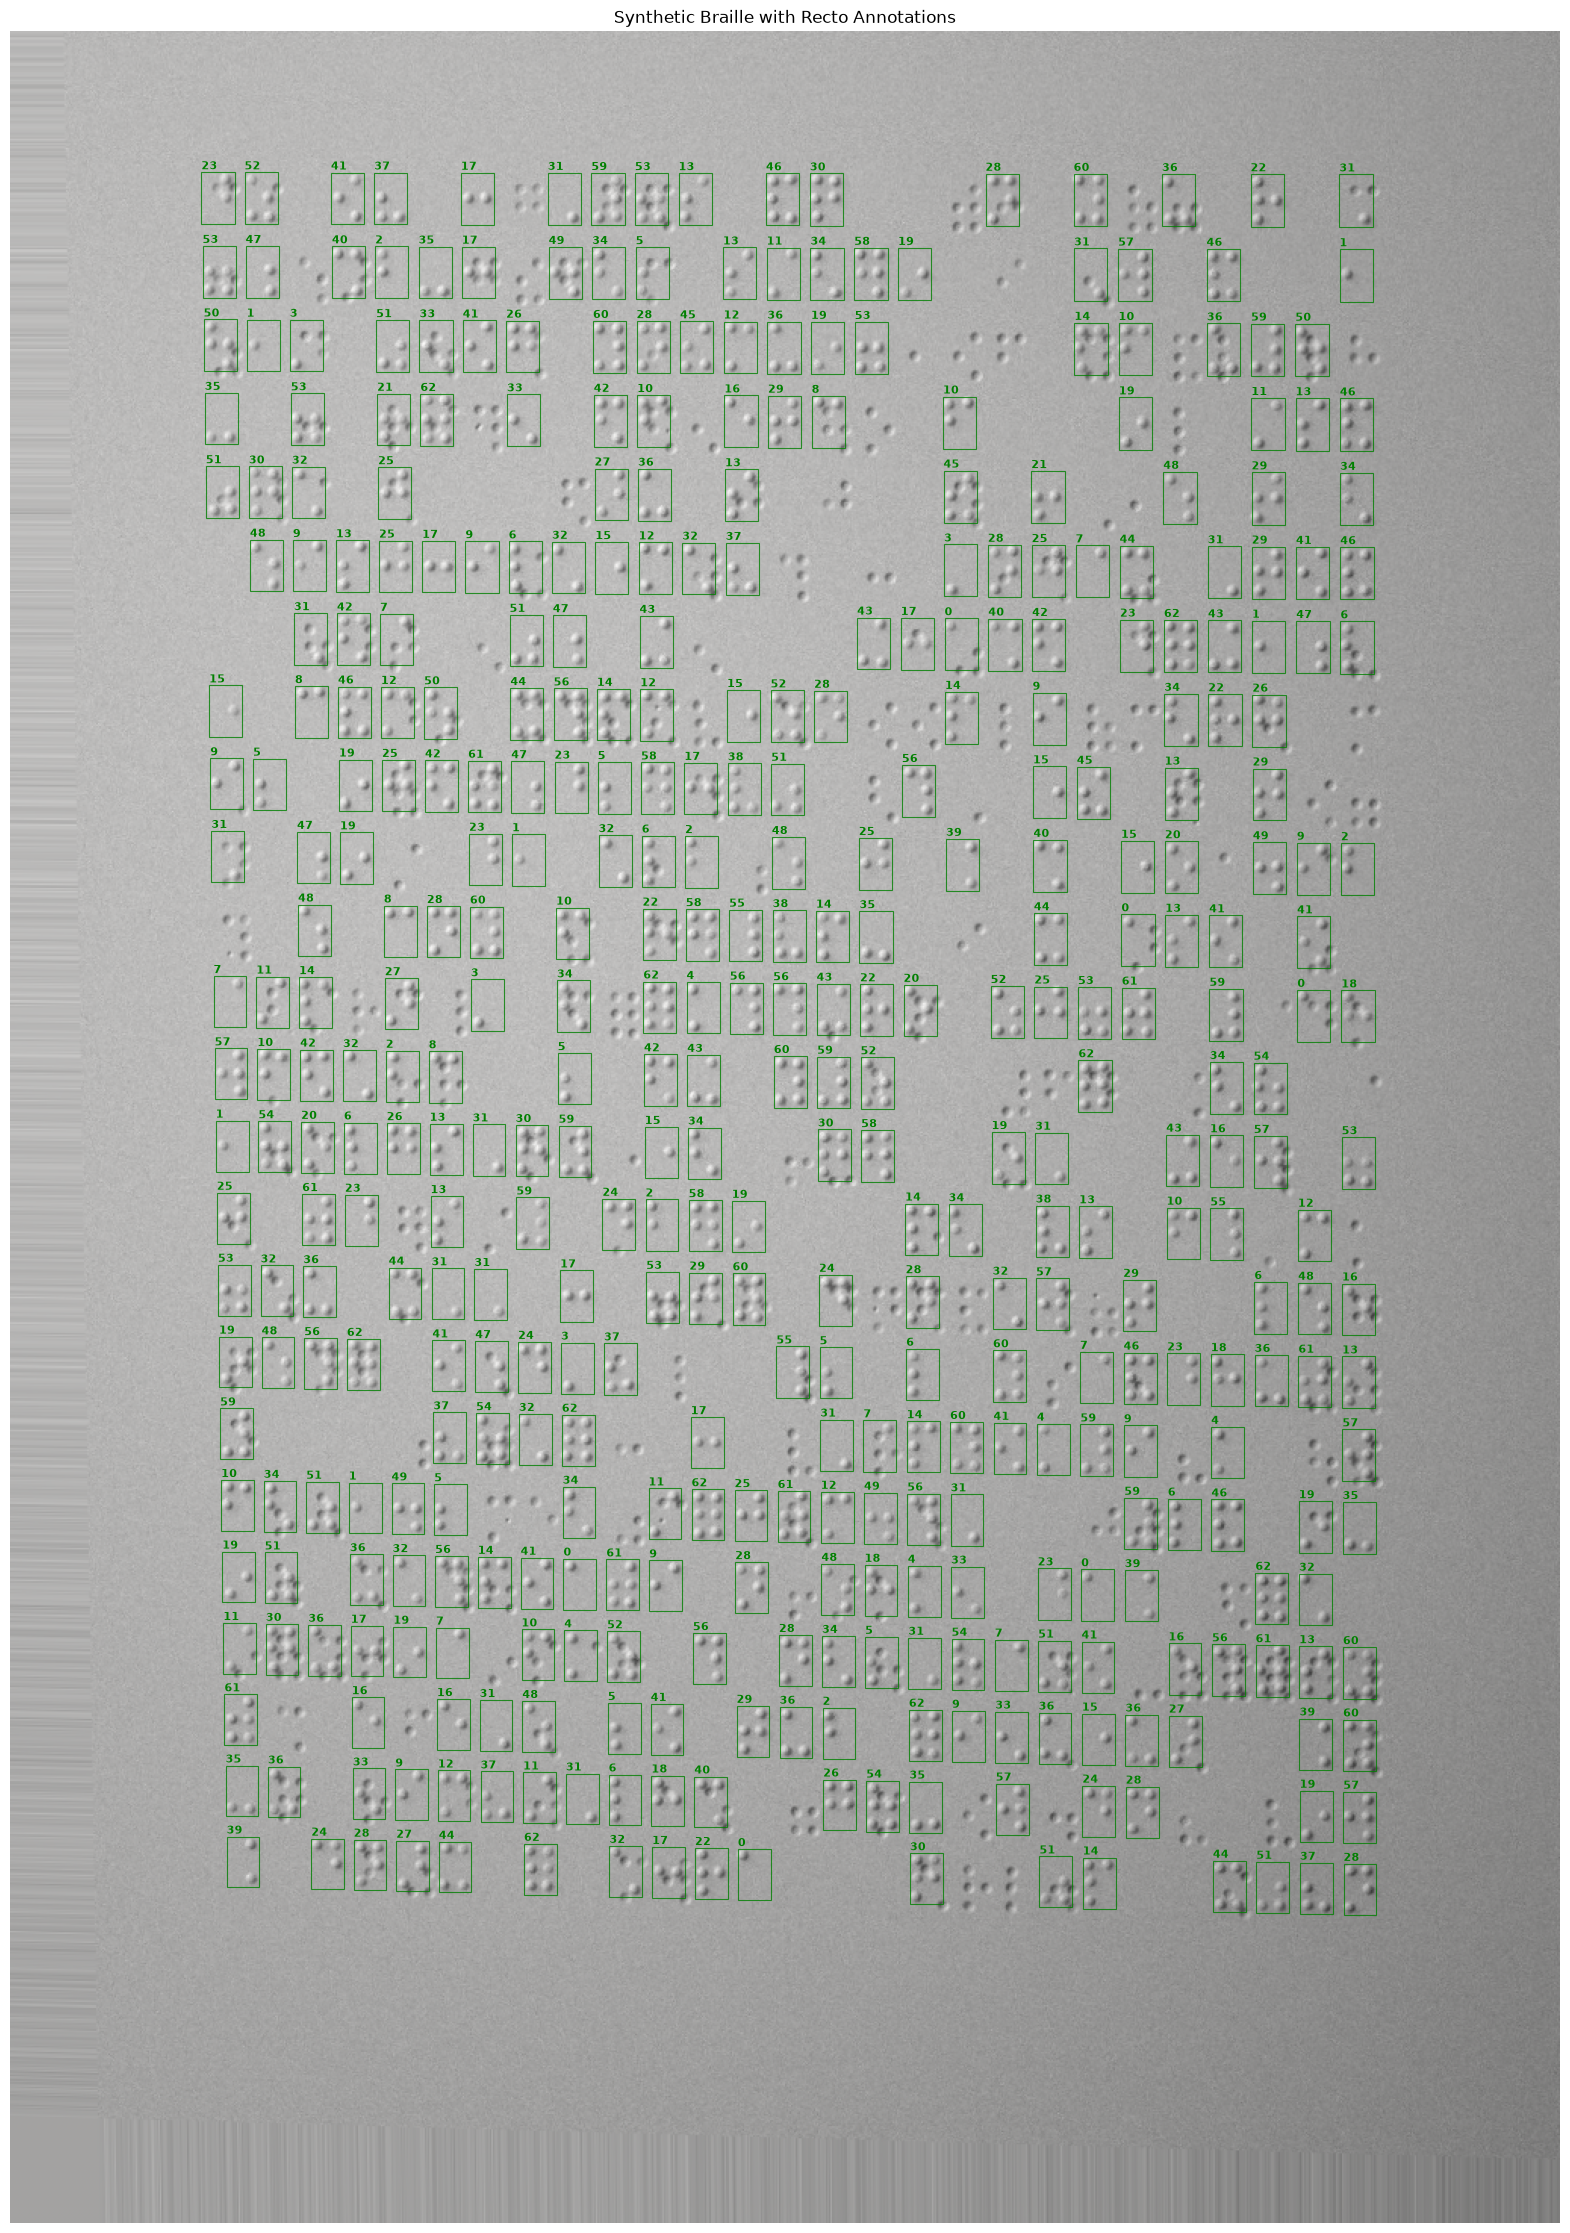

In [1142]:
gen = BrailleGenerator(scale=5)
# allowed_chars=[]
img, annotations = gen.generate_page()
print(annotations[:5])
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

cv2.imwrite(img=img, filename="test-synthesized.jpg")
# plt.figure(figsize=(40, 20))
# plt.axis("off")
# plt.imshow(img)
# plt.show()

visualize_braille_annotations(img, annotations)

In [1143]:
def build_yolo_dataset(generator, num_samples=100, output_dir="braille_dataset", split_ratios=(0.8, 0.1, 0.1)):
    """
    Generates a dataset and splits it into train/val/test folders.
    split_ratios defines the distribution (Train, Validation, Test).
    """
    # Validate ratios sum to 1.0
    assert abs(sum(split_ratios) - 1.0) < 1e-5, "Split ratios must sum to 1.0"
    
    # Calculate exact counts for each split
    train_count = int(num_samples * split_ratios[0])
    val_count = int(num_samples * split_ratios[1])
    
    # Create a list mapping each sample to a split, then shuffle it
    splits = ['train'] * train_count + ['val'] * val_count
    splits += ['test'] * (num_samples - len(splits)) # Give remainder to test
    random.shuffle(splits)
    
    # Set up directory structure
    base_path = Path(output_dir)
    for folder in ['images', 'labels']:
        for split in ['train', 'val', 'test']:
            (base_path / folder / split).mkdir(parents=True, exist_ok=True)
            
    print(f"Creating {num_samples} samples in '{output_dir}'...")
    
    for i, split in enumerate(splits):
        # Generate the synthetic image and YOLO annotations
        img_bgr, annotations = generator.generate_page()
        
        # Define zero-padded filenames (e.g., sample_00042.jpg)
        base_filename = f"sample_{i:05d}"
        img_path = base_path / 'images' / split / f"{base_filename}.jpg"
        lbl_path = base_path / 'labels' / split / f"{base_filename}.txt"
        
        # Save image using OpenCV
        cv2.imwrite(str(img_path), img_bgr)
        
        # Save annotations as a text file
        with open(lbl_path, 'w') as f:
            # Join list of annotation strings with newlines
            f.write('\n'.join(annotations))
            
        # Optional progress tracking
        if (i + 1) % max(1, (num_samples // 10)) == 0 or (i + 1) == num_samples:
            print(f"Generated {i + 1}/{num_samples}...")

    print("\nDataset Generation Complete!")
    print("-" * 30)
    print(f"Train samples: {splits.count('train')}")
    print(f"Val samples:   {splits.count('val')}")
    print(f"Test samples:  {splits.count('test')}")
    print("-" * 30)

In [1144]:
# build_yolo_dataset(
#         generator=gen, 
#         num_samples=500, 
#         output_dir="../data/synthetic", 
#         split_ratios=(0.7, 0.2, 0.1)
#     )